# 02 EDA: Food.com recipes

Food.com (Majumder et al., EMNLP 2019) gives us what What's Cooking lacks for a recommender:
recipe **names**, **steps**, **cooking time**, **tags** and **user ratings**.

Questions:
1. What do the recipes look like (size, time, steps)?
2. Which cuisines are tagged?
3. How clean are the ingredients, and what does the authors' ingredient map (`ingr_map.pkl`) fix?
4. What do the ratings look like?
5. How much do Food.com and What's Cooking share? (can we use one ingredient vocabulary?)

Files in `data/raw/`: `RAW_recipes.csv`, `RAW_interactions.csv`, `ingr_map.pkl` (Kaggle: shuyangli94/food-com-recipes-and-user-interactions).

In [1]:
import ast
import json
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

recipes = pd.read_csv("../data/raw/RAW_recipes.csv")

# list columns are stored as text like "['salt', 'butter']" -> turn them into real lists
for col in ["ingredients", "tags", "steps"]:
    recipes[col] = recipes[col].apply(ast.literal_eval)

recipes[["name", "id", "minutes", "n_steps", "n_ingredients", "ingredients"]].head()

,name,id,minutes,n_steps,n_ingredients,ingredients
0,arriba baked winter squash mexican style,137739,55,11,7,"[winter squash, mexican seasoning, mixed spice..."
1,a bit different breakfast pizza,31490,30,9,6,"[prepared pizza crust, sausage patty, eggs, mi..."
2,all in the kitchen chili,112140,130,6,13,"[ground beef, yellow onions, diced tomatoes, t..."
3,alouette potatoes,59389,45,11,11,"[spreadable cheese with garlic and herbs, new ..."
4,amish tomato ketchup for canning,44061,190,5,8,"[tomato juice, apple cider vinegar, sugar, sal..."


## 1. Size and missing values

In [2]:
print("recipes:", len(recipes))
print("unique ids:", recipes["id"].nunique())
recipes.isna().sum()

recipes: 231637
unique ids: 231637


name                 1
id                   0
minutes              0
contributor_id       0
submitted            0
tags                 0
nutrition            0
n_steps              0
steps                0
description       4979
ingredients          0
n_ingredients        0
dtype: int64

## 2. Recipe size, cooking time, steps

In [3]:
print(recipes[["n_ingredients", "n_steps", "minutes"]].describe().round(1))
print()
print("recipes longer than 1 day:", (recipes["minutes"] > 24 * 60).sum())
print("recipes with 0 minutes:", (recipes["minutes"] == 0).sum())

       n_ingredients   n_steps       minutes
count       231637.0  231637.0  2.316370e+05
mean             9.1       9.8  9.398500e+03
std              3.7       6.0  4.461963e+06
min              1.0       0.0  0.000000e+00
25%              6.0       6.0  2.000000e+01
50%              9.0       9.0  4.000000e+01
75%             11.0      12.0  6.500000e+01
max             43.0     145.0  2.147484e+09

recipes longer than 1 day: 2000
recipes with 0 minutes: 1094


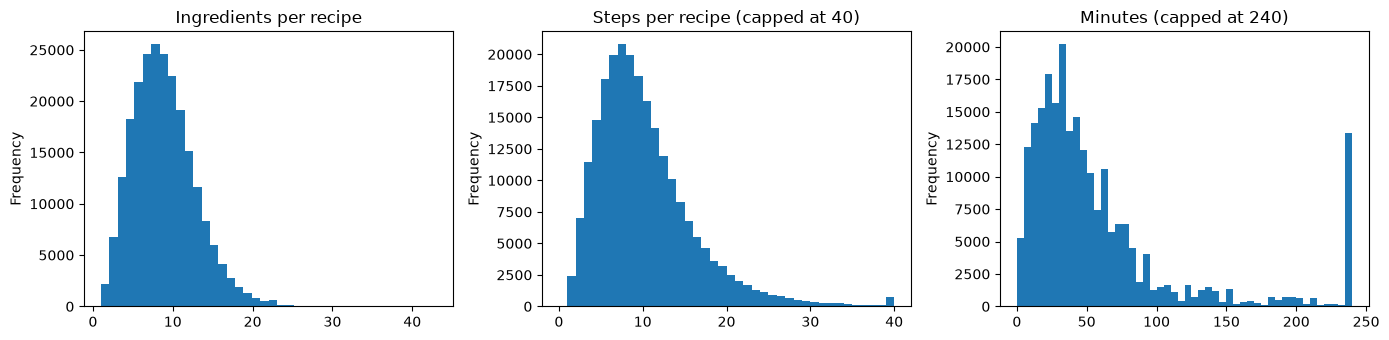

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
recipes["n_ingredients"].plot(kind="hist", bins=40, ax=ax[0], title="Ingredients per recipe")
recipes["n_steps"].clip(upper=40).plot(kind="hist", bins=40, ax=ax[1], title="Steps per recipe (capped at 40)")
recipes["minutes"].clip(upper=240).plot(kind="hist", bins=48, ax=ax[2], title="Minutes (capped at 240)")
plt.tight_layout()
plt.show()

## 3. Cuisine tags

distinct tags: 552
recipes with a cuisine tag: 39024 (17%)
recipes with 2+ cuisine tags: 2804


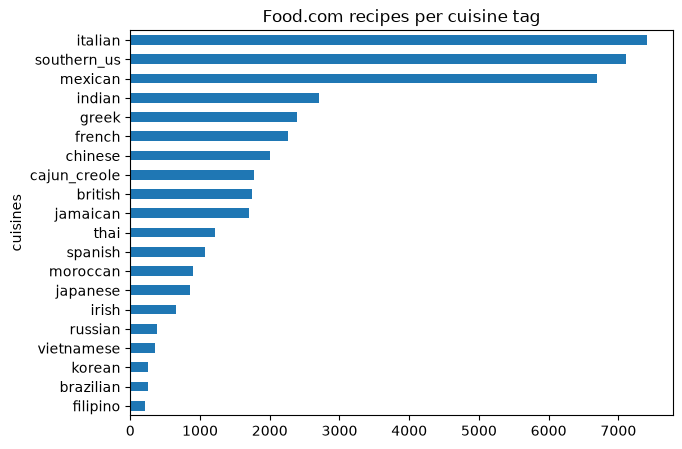

In [5]:
tag_counts = Counter(t for tags in recipes["tags"] for t in tags)
print("distinct tags:", len(tag_counts))

# Food.com tag -> What's Cooking cuisine name (18 of the 20 exist; 'english' ~ british, 'caribbean' ~ jamaican)
cuisine_tags = {
    "italian": "italian", "mexican": "mexican", "southern-united-states": "southern_us",
    "indian": "indian", "chinese": "chinese", "french": "french", "cajun": "cajun_creole",
    "creole": "cajun_creole", "thai": "thai", "japanese": "japanese", "greek": "greek",
    "spanish": "spanish", "korean": "korean", "vietnamese": "vietnamese", "moroccan": "moroccan",
    "english": "british", "irish": "irish", "caribbean": "jamaican", "russian": "russian",
    "brazilian": "brazilian", "filipino": "filipino",
}

def find_cuisines(tags):
    return sorted({cuisine_tags[t] for t in tags if t in cuisine_tags})

recipes["cuisines"] = recipes["tags"].apply(find_cuisines)
n_tagged = (recipes["cuisines"].str.len() > 0).sum()
print("recipes with a cuisine tag:", n_tagged, f"({n_tagged / len(recipes):.0%})")
print("recipes with 2+ cuisine tags:", (recipes["cuisines"].str.len() > 1).sum())

cuisine_counts = recipes["cuisines"].explode().value_counts()
cuisine_counts.plot(kind="barh", figsize=(7, 5), title="Food.com recipes per cuisine tag")
plt.gca().invert_yaxis()
plt.show()

## 4. Ingredients and the ingredient map

In [6]:
ingredient_counts = Counter(i for lst in recipes["ingredients"] for i in lst)
freq = pd.Series(ingredient_counts).sort_values(ascending=False)

print("distinct ingredient names:", len(freq))
print("used only once:", (freq == 1).sum())
print("used 20 times or more:", (freq >= 20).sum())
print("salt is in", round(freq["salt"] / len(recipes) * 100), "% of recipes")
freq.head(15)

distinct ingredient names: 14942
used only once: 3546
used 20 times or more: 4418
salt is in 37 % of recipes


salt                 85746
butter               54975
sugar                44535
onion                39065
water                34914
eggs                 33761
olive oil            32822
flour                26266
milk                 25786
garlic cloves        25748
pepper               22319
brown sugar          18655
garlic               18087
all-purpose flour    17659
baking powder        17504
dtype: int64

In [7]:
# ingr_map.pkl: the authors' cleaning table, raw ingredient string -> canonical name ('replaced')
ingr_map = pd.read_pickle("../data/raw/ingr_map.pkl")
to_canonical = dict(zip(ingr_map["raw_ingr"], ingr_map["replaced"]))

covered = sum(c for name, c in ingredient_counts.items() if name in to_canonical)
print("ingredient uses covered by the map:", f"{covered / freq.sum():.1%}")
print("distinct names:", len(freq), "-> canonical names:", ingr_map["replaced"].nunique())

# what does the map merge? canonical names with the most raw variants
variants = ingr_map.groupby("replaced")["raw_ingr"].agg(["size", lambda x: " | ".join(x.head(4))])
variants.columns = ["n_raw_names", "examples"]
variants.sort_values("n_raw_names", ascending=False).head(8)

ingredient uses covered by the map: 99.8%
distinct names: 14942 -> canonical names: 8023


,n_raw_names,examples
replaced,,
dressing,163,hidden valley original ranch dressing and seas...
sausage,154,johnsonville hot & spicy breakfast sausage | j...
chile,99,green chile sauce with pork | garlic and red c...
cake mix,85,duncan hines moist deluxe butter recipe fudge ...
cheddar,84,kraft shredded triple cheddar cheese with a to...
tortilla,82,8-inch 97% fat free flour tortillas | nacho ch...
pickle,79,bread and butter pickle juice | vlasic dill pi...
lettuce,42,"medium heads bibb or red leaf lettuce, washed,..."


**Careful: the map has bugs.** Some canonical names are corrupted ("flour" → "flmy": the
authors replaced "our" by "my" inside words) and some merges are wrong. Check before using it:

In [8]:
corrupted = ingr_map[ingr_map["replaced"].str.contains("flmy")]
print("entries with 'flmy':", len(corrupted))

# merges where the canonical name shares no word with the raw name (ignoring plurals): worth a look
def roots(text):
    return {w.rstrip("s") for w in text.lower().replace("-", " ").split()}

def shares_a_word(row):
    return bool(roots(row["replaced"]) & roots(row["raw_ingr"]))

suspicious = ingr_map[~ingr_map.apply(shares_a_word, axis=1)]
print("merges sharing no word with the raw name:", len(suspicious))
suspicious[["raw_ingr", "replaced", "count"]].sort_values("count", ascending=False).head(12)

entries with 'flmy': 106
merges sharing no word with the raw name: 218


,raw_ingr,replaced,count
4754,flour,flmy,23078
4753,gluten-free flour,flmy,23078
4752,bread machine flour,flmy,23078
2473,spring onions,scallion,14377
2466,green onion tops,scallion,14377
2472,green onion,scallion,14377
2459,green onion dip mix,scallion,14377
2465,green onion stems,scallion,14377
2462,dried green onion flakes,scallion,14377
2467,green onion dip,scallion,14377


In [9]:
# apply the map, fixing the 'flmy' bug
to_canonical = {raw: canon.replace("flmy", "flour") for raw, canon in to_canonical.items()}
recipes["ingredients_canonical"] = recipes["ingredients"].apply(
    lambda lst: sorted({to_canonical.get(i, i) for i in lst})
)
canon_freq = pd.Series(Counter(i for lst in recipes["ingredients_canonical"] for i in lst)).sort_values(ascending=False)
print("canonical ingredients used 20 times or more:", (canon_freq >= 20).sum())
canon_freq.head(15)

canonical ingredients used 20 times or more: 3544


salt                 85763
butter               55086
egg                  50466
onion                48728
sugar                44535
olive oil            40891
garlic clove         35275
water                34914
milk                 28334
flour                26431
pepper               22319
brown sugar          18655
garlic               18087
all-purpose flour    17664
baking powder        17555
dtype: int64

## 5. Ratings

reviews: 1132367 | users: 226570
rating = 0 (review without a rating): 5.4%


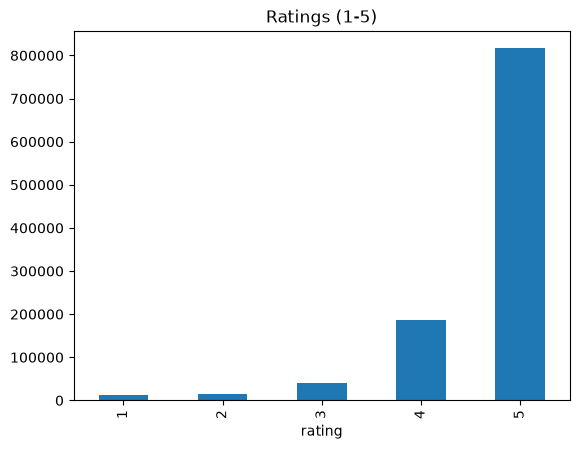

In [10]:
interactions = pd.read_csv("../data/raw/RAW_interactions.csv", usecols=["user_id", "recipe_id", "rating"])
print("reviews:", len(interactions), "| users:", interactions["user_id"].nunique())
print("rating = 0 (review without a rating):", f"{(interactions['rating'] == 0).mean():.1%}")

rated = interactions[interactions["rating"] > 0]
rated["rating"].value_counts().sort_index().plot(kind="bar", title="Ratings (1-5)")
plt.show()

In [11]:
per_recipe = rated.groupby("recipe_id")["rating"].agg(n_reviews="size", mean_rating="mean")
print(per_recipe["n_reviews"].describe().round(1))
print("recipes with 5+ rated reviews:", (per_recipe["n_reviews"] >= 5).sum())
print("most reviewed:")
per_recipe.join(recipes.set_index("id")["name"]).sort_values("n_reviews", ascending=False).head(5)

count    226590.0
mean          4.7
std          16.6
min           1.0
25%           1.0
50%           2.0
75%           4.0
max        1496.0
Name: n_reviews, dtype: float64
recipes with 5+ rated reviews: 50978
most reviewed:


,n_reviews,mean_rating,name
recipe_id,,,
27208,1496,4.589572,to die for crock pot roast
89204,1488,4.478495,crock pot chicken with black beans cream cheese
2886,1401,4.819415,best banana bread
39087,1359,4.838852,creamy cajun chicken pasta
67256,1194,4.793132,best ever banana cake with cream cheese frosting


## 6. Overlap with What's Cooking

In [12]:
with open("../data/raw/train.json", encoding="utf-8") as f:
    wc = json.load(f)
wc_counts = Counter(i.lower() for r in wc for i in r["ingredients"])

shared = set(wc_counts) & set(ingredient_counts)
share_uses = sum(wc_counts[i] for i in shared) / sum(wc_counts.values())
print("What's Cooking distinct ingredients:", len(wc_counts))
print("found exactly in Food.com:", len(shared))
print(f"share of What's Cooking ingredient USES covered: {share_uses:.0%}")

What's Cooking distinct ingredients: 6703
found exactly in Food.com: 3256
share of What's Cooking ingredient USES covered: 84%


In [13]:
# frequent What's Cooking ingredients with no exact match in Food.com -> cleaning to-do
missing = [(name, n) for name, n in wc_counts.most_common(500) if name not in ingredient_counts]
pd.DataFrame(missing[:20], columns=["what's cooking name", "recipes"])

,what's cooking name,recipes
0,large eggs,2948
1,extra-virgin olive oil,2747
2,grated parmesan cheese,1886
3,corn starch,1757
4,jalapeno chilies,1730
5,chopped cilantro fresh,1698
6,minced garlic,1583
7,chopped onion,1251
8,freshly ground pepper,949
9,large garlic cloves,873


## Summary

- 231,637 recipes with names, steps, time and tags; about 9 ingredients per recipe (median 40 min).
  Some cooking times are absurd (> 1 day, or 0) → cap or ignore them.
- 21 Food.com tags correspond to What's Cooking cuisines (all 20 cuisines covered, with
  *english ≈ british* and *caribbean ≈ jamaican*), but only 17% of recipes (39,024) have one.
- Ingredients are much cleaner than in What's Cooking (14,942 names; salt in 37% of recipes).
  The authors' map (`ingr_map.pkl`) reduces them to 8,023 canonical names, mostly by merging
  plurals and brand names, **but it has bugs**: "flour" became "flmy" (106 entries, easy to fix) and a
  few merges are wrong (e.g. *blanched slivered almonds* → *liver*). Use it only with fixes and checks.
- 1.13M reviews, ratings very positive (mostly 5); 5% are reviews without a rating (0).
  Median 2 rated reviews per recipe; 50,978 recipes have 5 or more →
  use ratings only as a tie-breaker / popularity signal.
- 84% of What's Cooking ingredient uses already match Food.com names exactly; the rest are
  mostly modifiers (*large eggs*, *chopped onion*, *extra-virgin olive oil*) or spellings (*tumeric*, *mayonaise*).

**Implication for the project:** map both datasets onto the Food.com canonical names (Théodore),
use What's Cooking for the cuisine/graph analysis and Food.com as the recipe catalogue of the recommender.